# Eco-Concrete Strength Modeling (Notebook 2)
## Cross-Validation, Tuning, and Publication-Ready Outputs

**Goal:** Make your modeling results **more defensible** by adding cross-validation, basic hyperparameter tuning, and exportable figures/tables for the paper + GitHub

### What this notebook adds:
1. Robust data loading (Local or Colab + Google Drive)
2. Cross-validation evaluation (R², MAE)
3. Simple hyperparameter tuning (Random Forest + Gradient Boosting)
4. “Holdout test” evaluation on an untouched test set
5. Publication-ready outputs:
   - figures saved to `./figures/`
   - results tables saved to `./outputs/`
6. A sustainability proxy section

---
## Expected folder structure example (recommended)
If running locally or in a Drive-synced folder:
```
Research Project/
  notebooks/
    02_eco_concrete_cv_tuning_outputs.ipynb
  data/
    Concrete_Data.csv
  figures/
  outputs/
  src/
```


In [ ]:
# Installs dependencies when running in Google Colab.
# If these packages are already installed, this cell will finish quickly.
!pip -q install scikit-learn pandas numpy matplotlib

import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning tools
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GroupKFold,
    GroupShuffleSplit,
    cross_validate,
    GridSearchCV,
)
from sklearn.metrics import r2_score, mean_absolute_error, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Ensures repeatability
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Output prefix keeps baseline results separate from future RCA results
OUTPUT_PREFIX = "baseline"

# Default output folders. These are replaced by the data-loading cell when Drive/repo paths are set.
FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Setup complete.")


Setup complete.


## 1) Data loading options (Local vs Colab)

### Option A: relative `data/` folder (local or Drive-synced)
Keep your CSV here:
```
./data/Concrete_Data.csv
```

### Option B: Colab + Google Drive
Mount Drive, then set `BASE_DIR` to your Drive path (example below).

> Tip: In Colab, Drive paths look like `/content/drive/MyDrive/...`

The same CSV used in 01_baseline_strength_model.ipynb should be used in this notebook as well


In [ ]:
# ============================================================
# Project configuration
# ============================================================
# Default: Google Drive, because that is the current workflow
# For GitHub/repo execution later, set the environment variable:
# ECO_CONCRETE_RUN_MODE=repo
RUN_MODE = os.environ.get("ECO_CONCRETE_RUN_MODE", "drive").strip().lower()
EXPECTED_CSV = "concrete_data.csv"

# Mounts drive and establishes dataset
if RUN_MODE == "drive":
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError(
            "RUN_MODE='drive' requires Google Colab. "
            "Run this notebook in Colab or set ECO_CONCRETE_RUN_MODE=repo."
        ) from exc

    drive.mount("/content/drive")
    BASE_DIR = Path(
        os.environ.get(
            "ECO_CONCRETE_DRIVE_BASE",
            "/content/drive/MyDrive/Indigo Research Project",
        )
    )

# Repo alternative: this makes the notebook runnable from GitHub later
elif RUN_MODE == "repo":
    cwd = Path.cwd()
    BASE_DIR = cwd.parent if cwd.name == "notebooks" else cwd

else:
    raise ValueError("RUN_MODE must be either 'drive' or 'repo'.")

# Output folders
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
OUT_DIR = BASE_DIR / "outputs"

csv_path = DATA_DIR / EXPECTED_CSV
if not csv_path.exists():
    raise FileNotFoundError(
        f"Could not find the real baseline dataset at:\n{csv_path}\n\n"
        "Place concrete_data.csv in the project's data folder before continuing."
    )

# Loads CSV into dataframe
df = pd.read_csv(csv_path)

FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Creates a backup of the raw dataset
df_raw = pd.read_csv(csv_path)

# Clean column-name spacing immediately.
df.columns = df.columns.str.strip()

# Displays set-up details for verification
print("RUN_MODE:", RUN_MODE)
print("BASE_DIR:", BASE_DIR)
print("Dataset:", csv_path)
print("Raw shape:", df_raw.shape)
df_raw.head()

Mounted at /content/drive
RUN_MODE: drive
BASE_DIR: /content/drive/MyDrive/Indigo Research Project
Dataset: /content/drive/MyDrive/Indigo Research Project/data/concrete_data.csv
Raw shape: (1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 2) Clean column names + identify target

Different versions of the dataset sometimes have slightly different column names.
We’ll standardize the column names (lowercase, underscores), search for duplicates, ensure all the necessary columns are present, and check for realistic values

Most errors will require manual fixes or a different dataset.


In [ ]:
# Normalizes the dataset to improve model speed and accuracy
def normalize_col(name: str) -> str:
    """Convert a column label to lowercase snake_case."""
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return re.sub(r"_+", "_", name).strip("_")

# Specifically searches for exact target and feature columns
def canonical_name(normalized: str) -> str:
    """Map known UCI column labels to a fixed baseline schema."""
    if "concrete_compressive_strength" in normalized or normalized.startswith("compressive_strength"):
        return "concrete_compressive_strength_mpa"
    if normalized.startswith("blast_furnace_slag"):
        return "blast_furnace_slag"
    if normalized.startswith("fly_ash"):
        return "fly_ash"
    if normalized.startswith("superplasticizer"):
        return "superplasticizer"
    if normalized.startswith("coarse_aggregate"):
        return "coarse_aggregate"
    if normalized.startswith("fine_aggregate"):
        return "fine_aggregate"
    if normalized.startswith("cement"):
        return "cement"
    if normalized.startswith("water"):
        return "water"
    if normalized.startswith("age"):
        return "age"
    return normalized

# Creates a backup, then cleans and standardizes the CSV columns for an expected format
df = df_raw.copy()
normalized = [normalize_col(c) for c in df.columns]
canonical = [canonical_name(c) for c in normalized]

# Checks for duplications during the standardization process
# If error occurs, lists the duplicates for fixing
if len(canonical) != len(set(canonical)):
    duplicates = pd.Series(canonical)[pd.Series(canonical).duplicated(keep=False)].tolist()
    raise ValueError(
        "Column normalization created duplicate names. "
        f"Resolve these columns manually: {duplicates}"
    )

# Renames all columns to the standardized canonical names
# Uses listed names as machine learning inputs
df.columns = canonical

BASELINE_FEATURES = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
]
MIX_COLUMNS = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
]

# Additional checks to ensure all the required columns are present in the CSV
TARGET_COL = "concrete_compressive_strength_mpa"
REQUIRED_COLUMNS = BASELINE_FEATURES + [TARGET_COL]

missing_columns = [c for c in REQUIRED_COLUMNS if c not in df.columns]
if missing_columns:
    raise KeyError(
        f"Missing required UCI columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

for column in REQUIRED_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

missing_counts = df[REQUIRED_COLUMNS].isna().sum()
problem_columns = missing_counts[missing_counts > 0]
if not problem_columns.empty:
    raise ValueError(
        "Missing or nonnumeric values remain in required columns:\n"
        f"{problem_columns.to_string()}"
    )

# Checks for realistic values in the CSV columns
values = df[REQUIRED_COLUMNS].to_numpy(dtype=float)
if not np.isfinite(values).all():
    raise ValueError("The dataset contains nonfinite values in required columns.")

if (df[BASELINE_FEATURES] < 0).any().any():
    raise ValueError("One or more mixture features contain negative values.")

if (df["age"] <= 0).any() or (df[TARGET_COL] <= 0).any():
    raise ValueError("Age and compressive strength must be strictly positive.")

duplicate_rows = int(df.duplicated(subset=REQUIRED_COLUMNS).sum())
repeated_mix_rows = int(df.duplicated(subset=MIX_COLUMNS, keep=False).sum())

# Defines the columns into machine learning variables
X = df[BASELINE_FEATURES].copy()
y = df[TARGET_COL].copy()

print("Validated shape:", df.shape)
print("Exact duplicate rows:", duplicate_rows)
print("Rows belonging to repeated base mixture compositions:", repeated_mix_rows)
print("Features:", BASELINE_FEATURES)
df[REQUIRED_COLUMNS].describe().T

Validated shape: (1030, 9)
Exact duplicate rows: 25
Rows belonging to repeated base mixture compositions: 784
Features: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
blast_furnace_slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
fly_ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
coarse_aggregate,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
fine_aggregate,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
concrete_compressive_strength_mpa,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


## 3) Holdout split and cross-validation design

Repeated base mixture compositions are kept together where possible so that the same recipe is not placed in both training and testing due to a difference in age.


In [ ]:
# Build a group label from mixture composition, excluding age and strength.
# If the same base composition appears at multiple ages, all of its rows stay
# together in either training or testing.
mix_groups = pd.util.hash_pandas_object(
    df[MIX_COLUMNS], index=False
).astype(str)

# Checks for number of distinct groups, then chooses a split method
# Group shuffle split prevents test data memorization if applicable
# Otherwise, code uses standard train test split
if mix_groups.nunique() < len(df):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=RANDOM_STATE,
    )
    train_idx, test_idx = next(splitter.split(X, y, groups=mix_groups))
    split_method = "grouped holdout split"
else:
    indices = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        indices,
        test_size=0.20,
        random_state=RANDOM_STATE,
    )
    split_method = "random row holdout split"

# Prevents modifications to the original dataset
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train = mix_groups.iloc[train_idx].copy()

# Checks for amount of groups and chooses a method
# GroupKFold prevents groups from being in both training and testing sets
# in 5 fold cross validation
# Otherwise use standard KFold with shuffling
if groups_train.nunique() >= 5 and groups_train.nunique() < len(groups_train):
    cv = GroupKFold(n_splits=5)
    cv_groups = groups_train
    cv_method = "5-fold GroupKFold"
else:
    cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_groups = None
    cv_method = "5-fold shuffled KFold"

print("Holdout method:", split_method)
print("Cross-validation method:", cv_method)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Holdout method: grouped holdout split
Cross-validation method: 5-fold GroupKFold
Train shape: (793, 8)
Test shape: (237, 8)


## 4. Baseline cross-validation on the training data
We compute mean ± STD for **R²** and **MAE** on the training set.

In [ ]:
def negative_mae_scorer():
    return make_scorer(mean_absolute_error, greater_is_better=False)

In [ ]:
# Defines the baseline models for testing
baseline_models = {
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "RandomForest": RandomForestRegressor(
        # Number of trees, improves quality of model prediction
        # Diminishing returns past 200 trees
        n_estimators=400,
        # Ensures repeatability
        random_state=RANDOM_STATE,
        # Determines memory consumption and training speed
        # "-1" -> utilizes all CPU cores available
        n_jobs=-1,
        # Minimum number of samples in final prediction of each tree
        # Prevents overfitting
        min_samples_leaf=1
    ),
    "GradientBoosting": GradientBoostingRegressor(
        # Ensures repeatability
        random_state=RANDOM_STATE,
    ),
}

# Runs cross-validation on training data as an initial test
# Higher "r2" value indicates how well the model fits training data
cv_rows = []
for name, model in baseline_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        groups=cv_groups,
        scoring={"r2": "r2", "mae": negative_mae_scorer()},
        return_train_score=False,
        n_jobs=1,
    )
    cv_rows.append({
        "model": name,
        "cv_r2_mean": float(np.mean(scores["test_r2"])),
        "cv_r2_std": float(np.std(scores["test_r2"], ddof=1)),
        "cv_mae_mean_mpa": float(-np.mean(scores["test_mae"])),
        "cv_mae_std_mpa": float(np.std(-scores["test_mae"], ddof=1)),
    })

# Stores results in the dataframe and ranks the models
# File is printed and saved for publication usage
cv_df = pd.DataFrame(cv_rows).sort_values(
    "cv_r2_mean", ascending=False
).reset_index(drop=True)

cv_path = OUT_DIR / f"baseline_model_comparison_cv_{OUTPUT_PREFIX}.csv"
cv_df.to_csv(cv_path, index=False)
print("Saved:", cv_path)
cv_df

Saved: /content/drive/MyDrive/Indigo Research Project/outputs/baseline_model_comparison_cv_baseline.csv


,model,cv_r2_mean,cv_r2_std,cv_mae_mean_mpa,cv_mae_std_mpa
0,GradientBoosting,0.843065,0.037257,4.796066,0.630029
1,RandomForest,0.836054,0.044353,4.684358,0.467065
2,LinearRegression,0.578600,0.068100,8.292083,0.740989


## 5. Hyperparameter tuning

`GridSearchCV` performs model selection only within the training data. The random forest itself uses one core so that parallelization is controlled by the grid search rather than nested at two levels.

In [ ]:
# Initializes random forest model
rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=1,
)

# Setting up a random forest hyperparameter grid for tuning
rf_grid = {
    # Number of trees
    "n_estimators": [200],
    # Maximum depth each individual decision tree (growth limit)
    "max_depth": [None, 10],
    # Minimum number of samples in final prediction of each tree
    "min_samples_leaf": [2],
}

# Print out best parameters and best cross-validation score
rf_search = GridSearchCV(
    estimator=rf,
    param_grid=rf_grid,
    cv=cv,
    scoring="r2",
    n_jobs=1,
    verbose=1,
    refit=True,
)
rf_search.fit(X_train, y_train, groups=cv_groups)

# Prints results
print("Best Random Forest parameters:", rf_search.best_params_)
print("Best Random Forest CV R²:", rf_search.best_score_)

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best Random Forest parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Best Random Forest CV R²: 0.8308673897332726


In [ ]:
# Initializes gradient boosting regressor
gbr = GradientBoostingRegressor(
    random_state=RANDOM_STATE,
)

# Same processes as previous cell
gbr_grid = {
    # Number of boosting stages or sequential decision trees
    "n_estimators": [150, 300],
    # Shrinkage factor, contribution of each individual tree
    "learning_rate": [0.05, 0.10],
    # Maximum depth of each individual regression tree
    # Controls complexity of each learner
    "max_depth": [2],
    # Minimum number of samples in final prediction of each tree
    "min_samples_leaf": [2],
    # Takes a fraction out of 1 of the training data for the next tree
    "subsample": [0.9],
}

# Print out best parameters and best cross-validation score
gbr_search = GridSearchCV(
    estimator=gbr,
    param_grid=gbr_grid,
    cv=cv,
    scoring="r2",
    n_jobs=1,
    verbose=1,
    refit=True,
)
gbr_search.fit(X_train, y_train, groups=cv_groups)

# Prints results
print("Best Gradient Boosting parameters:", gbr_search.best_params_)
print("Best Gradient Boosting CV R²:", gbr_search.best_score_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Gradient Boosting parameters: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 2, 'n_estimators': 300, 'subsample': 0.9}
Best Gradient Boosting CV R²: 0.8516106660715366


## 6. Select the final model from training-set cross-validation

Linear regression remains a reported baseline. Only the training data is used, and the selected final model is whichever candidate has the strongest training-set cross-validation R².

In [ ]:
# Finds the performance of a linear regression model
linear_cv_r2 = float(
    cv_df.loc[
        cv_df["model"] == "LinearRegression",
        "cv_r2_mean",
    ].iloc[0]
)

# Compiles all the r2 values into a set of variables
selection_cv_scores = {
    "LinearRegression": linear_cv_r2,
    "RandomForest_tuned": float(rf_search.best_score_),
    "GradientBoosting_tuned": float(gbr_search.best_score_),
}

# Searches for model with the highest r2 value
selected_name = max(selection_cv_scores, key=selection_cv_scores.get)

# Stores models for future usage
candidate_models = {
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "RandomForest_tuned": rf_search.best_estimator_,
    "GradientBoosting_tuned": gbr_search.best_estimator_,
}

# Prints results for viewing
print("CV scores used for selection:", selection_cv_scores)
print("Selected model:", selected_name)

CV scores used for selection: {'LinearRegression': 0.5786001029628061, 'RandomForest_tuned': 0.8308673897332726, 'GradientBoosting_tuned': 0.8516106660715366}
Selected model: GradientBoosting_tuned


## 7) Final held-out test evaluation

The test set is now used once to complete the final evaluations of each model. This is so that the model accuracy can be determined outside of the training set using new, unseen data.

In [ ]:
# Creates empty containers for storing data/models
test_rows = []
fitted_models = {}
test_predictions = {}

for name, model in candidate_models.items():
    # Prevents data leakage through cloning, then tests on untouched data
    fitted_model = clone(model).fit(X_train, y_train)
    pred = fitted_model.predict(X_test)

    # Saves all the results to the empty containers and checks the model
    # Calculates the r2 and MAE values
    fitted_models[name] = fitted_model
    test_predictions[name] = pred

    test_rows.append({
        "model": name,
        "selected_by_training_cv": name == selected_name,
        "selection_cv_r2": selection_cv_scores[name],
        "test_r2": float(r2_score(y_test, pred)),
        "test_mae_mpa": float(mean_absolute_error(y_test, pred)),
    })

# Ranks the models by r2
final_df = pd.DataFrame(test_rows).sort_values(
    "test_r2", ascending=False
).reset_index(drop=True)

# Saves table for publication
# Uses the prefix to specify type of dataset for publication purposes
final_path = OUT_DIR / f"test_set_results_{OUTPUT_PREFIX}.csv"
final_df.to_csv(final_path, index=False)
print("Saved:", final_path)
final_df

Saved: /content/drive/MyDrive/Indigo Research Project/outputs/test_set_results_baseline.csv


,model,selected_by_training_cv,selection_cv_r2,test_r2,test_mae_mpa
0,GradientBoosting_tuned,True,0.851611,0.887074,4.483934
1,RandomForest_tuned,False,0.830867,0.858259,5.026660
2,LinearRegression,False,0.578600,0.618233,9.029970


## 8) Publication-ready diagnostics

We’ll plot predicted vs actual for the best-performing model (by R²).


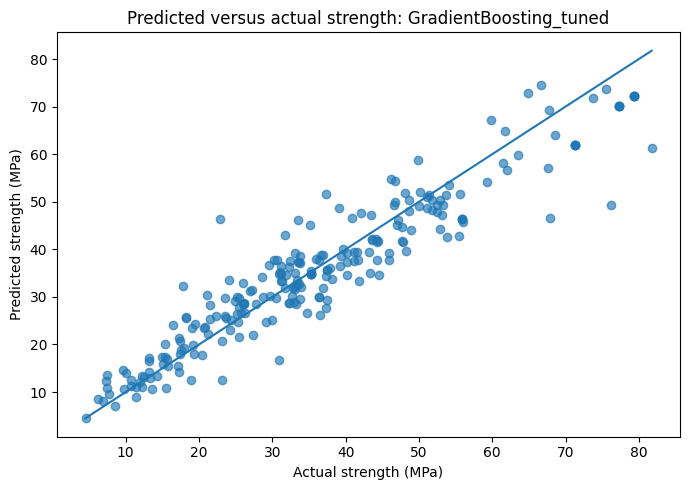

Saved: /content/drive/MyDrive/Indigo Research Project/figures/pred_vs_actual_GradientBoosting_tuned_baseline.png


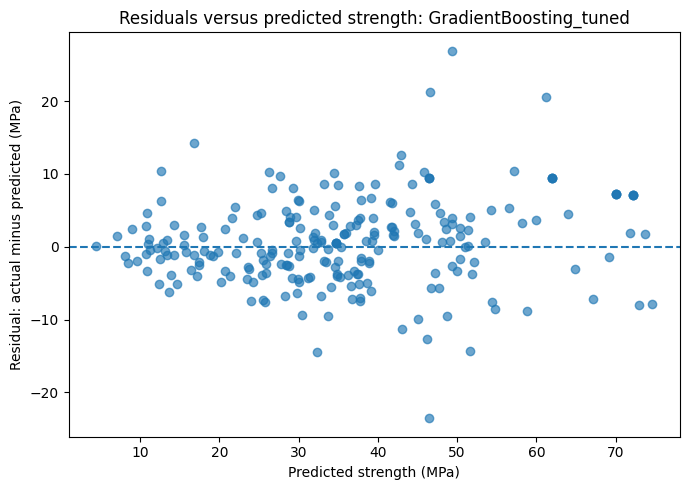

Saved: /content/drive/MyDrive/Indigo Research Project/figures/residual_plot_GradientBoosting_tuned_baseline.png


In [ ]:
# Defines best model and calculates residuals for graphing
selected_model = fitted_models[selected_name]
selected_pred = test_predictions[selected_name]
residuals = y_test.to_numpy() - selected_pred

# Predicted vs. Actual Strength
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, selected_pred, alpha=0.65)
# Places 45-degree line
# Provides a visual aid to determine model accuracy
minimum = min(float(y_test.min()), float(selected_pred.min()))
maximum = max(float(y_test.max()), float(selected_pred.max()))
ax.plot([minimum, maximum], [minimum, maximum])
ax.set_xlabel("Actual strength (MPa)")
ax.set_ylabel("Predicted strength (MPa)")
ax.set_title(f"Predicted versus actual strength: {selected_name}")
fig.tight_layout()
pred_path = FIG_DIR / f"pred_vs_actual_{selected_name}_{OUTPUT_PREFIX}.png"
fig.savefig(pred_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", pred_path)

# Residuals graph (Negative = Overpredicted, Positive = Underpredicted)
# Provides another way to graph model accuracy
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(selected_pred, residuals, alpha=0.65)
ax.axhline(0, linestyle="--")
ax.set_xlabel("Predicted strength (MPa)")
ax.set_ylabel("Residual: actual minus predicted (MPa)")
ax.set_title(f"Residuals versus predicted strength: {selected_name}")
fig.tight_layout()

# Saves figure for publication
residual_path = FIG_DIR / f"residual_plot_{selected_name}_{OUTPUT_PREFIX}.png"
fig.savefig(residual_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", residual_path)

**Predicted vs Actual Scatterplot:** While inaccurate predictions and outliers exist, the Gradient Boosting model seems to cluster around the plotted line, indicating reasonable model prediction accuracy.

**Residual Distribution Scatterplot:** Model accuracy is shown to be accurate, with most predicted values hovering within 5 MPa of the actual value. The model seems underpredicts at a lesser magnitude more frequently; however, it also overpredicts more often at a higher magnitude greater than 5 MPa of the actual value.

## 9) Permutation importance

Saved: /content/drive/MyDrive/Indigo Research Project/outputs/permutation_importance_GradientBoosting_tuned_baseline.csv


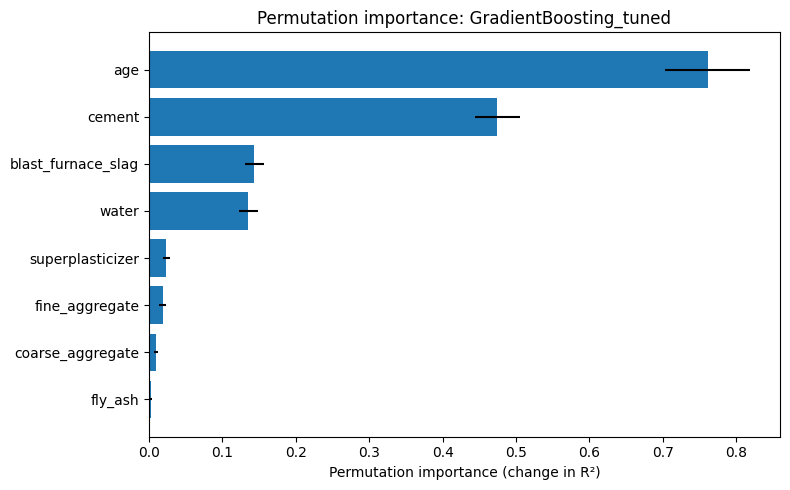

Saved: /content/drive/MyDrive/Indigo Research Project/figures/feature_importance_GradientBoosting_tuned_baseline.png


In [ ]:
# Measures importance of each variable using "r2" as a scoring metric
perm = permutation_importance(
    selected_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="r2",
)

# Sorts variables and provides mean + STD for each
importance_df = pd.DataFrame({
    "feature": BASELINE_FEATURES,
    "importance_mean_delta_r2": perm.importances_mean,
    "importance_std_delta_r2": perm.importances_std,
}).sort_values("importance_mean_delta_r2", ascending=False)

# Saves table for publication
importance_path = OUT_DIR / f"permutation_importance_{selected_name}_{OUTPUT_PREFIX}.csv"
importance_df.to_csv(importance_path, index=False)
print("Saved:", importance_path)

# Number of variables considered
top_k = 8
# Takes variables and reverses the horizontal bar order for plotting
top = importance_df.head(top_k).iloc[::-1]
# Plots results of previous code
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    top["feature"],
    top["importance_mean_delta_r2"],
    xerr=top["importance_std_delta_r2"],
)
ax.set_xlabel("Permutation importance (change in R²)")
ax.set_title(f"Permutation importance: {selected_name}")
fig.tight_layout()
# Saves graph for publication
importance_fig_path = FIG_DIR / f"feature_importance_{selected_name}_{OUTPUT_PREFIX}.png"
fig.savefig(importance_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", importance_fig_path)

**Feature Importance Bar Graph:** The model depends on age, cement, and blast furnace slag when predicting concrete compressive strength. This does not indicate direct physical causation, just the model's dependence when making predictions. However, even though this graph matches real-world observations to an extent, it's also important to note that low-importance variables, such as fly ash, do not reflect their significance in practical applications. Additionally, correlated variables can distort the permutation importance values.

## 10) Sustainability tradeoffs and Pareto candidates

**Important:** The current dataset does *not* include CO₂ emissions or cost. To determine sustainability, we create *proxies* from mixture composition.

This section uses literature-informed working factors expressed in consistent units:

- Emissions: `kg CO₂e per kg material`
- Cost: `USD per kg material`

Multiplying these factors by mixture quantities in `kg/m³` produces emissions in `kg CO₂e/m³` and material cost in `USD/m³`.

The highlighted points are **nondominated candidate mixtures within the observed held-out dataset**. They are not guaranteed global optima. Verify the exact references and regional applicability of all factors before manuscript submission.

The current values are defined by literature results and market value estimations as of June 2026.


In [ ]:
# ============================================================
# Working sustainability factors with corrected units
# ============================================================
# co2_kg_per_kg: kg CO2e per kg material
# cost_usd_per_kg: USD per kg material

# Current values should be defined or replaced by relevant literature results
# Current calculations uses GGBFS and natural aggregate data

RUN_SUSTAINABILITY_ANALYSIS = True
OVERWRITE_WORKING_FACTORS = False

# Compiles all relevant cost and sustainability data of each feature
# Includes literature sources, current relevance, and geographical location
working_factors = pd.DataFrame(
    [
        {
            "material": "cement",
            "co2_kg_per_kg": 0.830000,
            "cost_usd_per_kg": 0.072000,
            "source": "Mixture Optimization of Sustainable Concrete with Silica Fume Considering CO2 Emissions and Cost (Wang et al.); Emissions in CO2e/kg and cost converted to USD/kg from Table 1.",
            "year": "2022",
            "geography": "global emissions; cost source-specific",
        },
        {
            "material": "blast_furnace_slag",
            "co2_kg_per_kg": 0.143000,
            "cost_usd_per_kg": 0.054000,
            "source": "A Comprehensive Review on the Ground Granulated Blast Furnace Slag (GGBS) in Concrete Production (Ahmad et al.); 0.143 t CO2e/t GGBS in Table 2. USA price note: USD 54/t.",
            "year": "working literature value",
            "geography": "global emissions; USA cost",
        },
        {
            "material": "fly_ash",
            "co2_kg_per_kg": 0.000100,
            "cost_usd_per_kg": 0.126000,
            "source": "Optimizing calcium efficiency for sustainable cement with GGBFS-fly ash systems (Wattanachai et al.); 0.1 kg CO2e/tonne converted to kg CO2e/kg in Table 3. USA price note: USD 126/t.",
            "year": "2025",
            "geography": "source-specific emissions; USA cost",
        },
        {
            "material": "water",
            "co2_kg_per_kg": 0.000196,
            "cost_usd_per_kg": 0.000320,
            "source": "Mixture Optimization of Sustainable Concrete with Silica Fume Considering CO2 Emissions and Cost (Wang et al.); Emissions in CO2e/kg and cost converted to USD/kg from Table 1.",
            "year": "2022",
            "geography": "global emissions; cost source-specific",
        },
        {
            "material": "superplasticizer",
            "co2_kg_per_kg": 0.250000,
            "cost_usd_per_kg": 0.803200,
            "source": "Mixture Optimization of Sustainable Concrete with Silica Fume Considering CO2 Emissions and Cost (Wang et al.); Emissions in CO2e/kg and cost converted to USD/kg from Table 1.",
            "year": "2022",
            "geography": "global emissions; cost source-specific",
        },
        {
            "material": "coarse_aggregate",
            "co2_kg_per_kg": 0.007500,
            "cost_usd_per_kg": 0.009600,
            "source": "Mixture Optimization of Sustainable Concrete with Silica Fume Considering CO2 Emissions and Cost (Wang et al.); Emissions in CO2e/kg and cost converted to USD/kg from Table 1.",
            "year": "2022",
            "geography": "global emissions; cost source-specific",
        },
        {
            "material": "fine_aggregate",
            "co2_kg_per_kg": 0.002600,
            "cost_usd_per_kg": 0.008000,
            "source": "Mixture Optimization of Sustainable Concrete with Silica Fume Considering CO2 Emissions and Cost (Wang et al.); Emissions in CO2e/kg and cost converted to USD/kg from Table 1.",
            "year": "2022",
            "geography": "global emissions; cost source-specific",
        },
    ]
)

# Saves information to a CSV for publication purposes
factor_path = DATA_DIR / "sustainability_factors.csv"

# OVERWRITE_WORKING_FACTORS currently set to false since file is made in
# previous code
if OVERWRITE_WORKING_FACTORS or not factor_path.exists():
    working_factors.to_csv(factor_path, index=False)
    print("Created working factor file:", factor_path)
else:
    print("Using existing factor file:", factor_path)

working_factors

Using existing factor file: /content/drive/MyDrive/Indigo Research Project/data/sustainability_factors.csv


,material,co2_kg_per_kg,cost_usd_per_kg,source,year,geography
0,cement,0.830000,0.07200,Mixture Optimization of Sustainable Concrete w...,2022,global emissions; cost source-specific
1,blast_furnace_slag,0.143000,0.05400,A Comprehensive Review on the Ground Granulate...,working literature value,global emissions; USA cost
2,fly_ash,0.000100,0.12600,Optimizing calcium efficiency for sustainable ...,2025,source-specific emissions; USA cost
3,water,0.000196,0.00032,Mixture Optimization of Sustainable Concrete w...,2022,global emissions; cost source-specific
4,superplasticizer,0.250000,0.80320,Mixture Optimization of Sustainable Concrete w...,2022,global emissions; cost source-specific
5,coarse_aggregate,0.007500,0.00960,Mixture Optimization of Sustainable Concrete w...,2022,global emissions; cost source-specific
6,fine_aggregate,0.002600,0.00800,Mixture Optimization of Sustainable Concrete w...,2022,global emissions; cost source-specific


### 11) Identify Pareto-optimal mixtures

A mixture is **Pareto-optimal** if no other mixture is **higher strength** AND **lower emissions** at the same time. This isn’t a perfect optimization (because this dataset is observational), but it’s a clean way to show *tradeoffs*.

Saved: /content/drive/MyDrive/Indigo Research Project/outputs/sustainability_results_baseline.csv


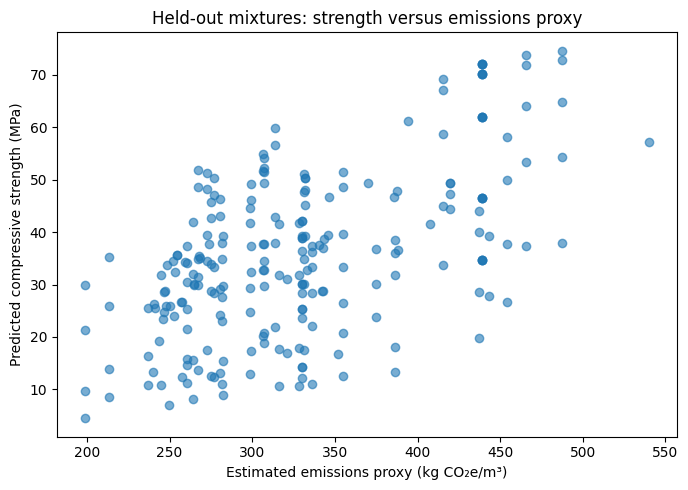

Saved: /content/drive/MyDrive/Indigo Research Project/figures/tradeoff_strength_vs_co2_proxy_baseline.png


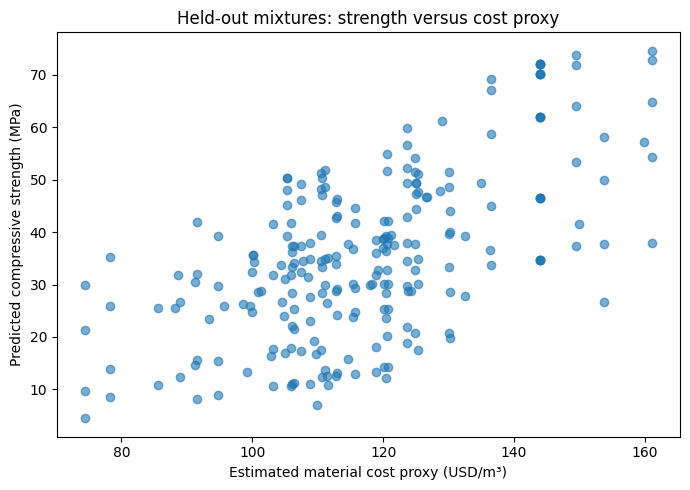

Saved: /content/drive/MyDrive/Indigo Research Project/figures/tradeoff_strength_vs_cost_proxy_baseline.png
Saved: /content/drive/MyDrive/Indigo Research Project/outputs/pareto_candidates_baseline.csv
Number of Pareto candidates: 20


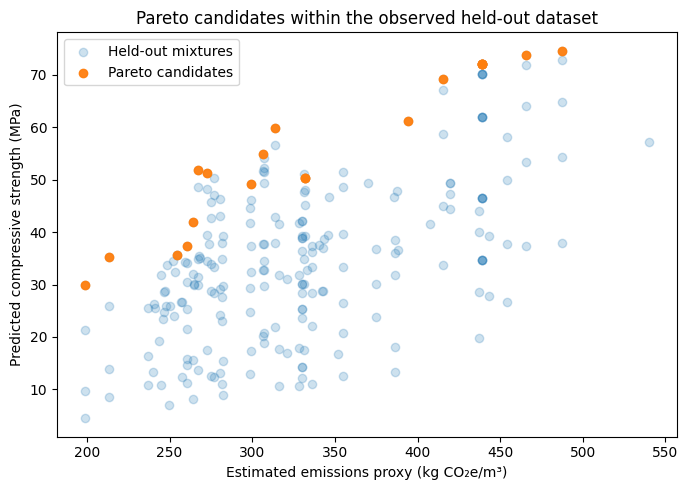

Saved: /content/drive/MyDrive/Indigo Research Project/figures/pareto_candidates_baseline.png


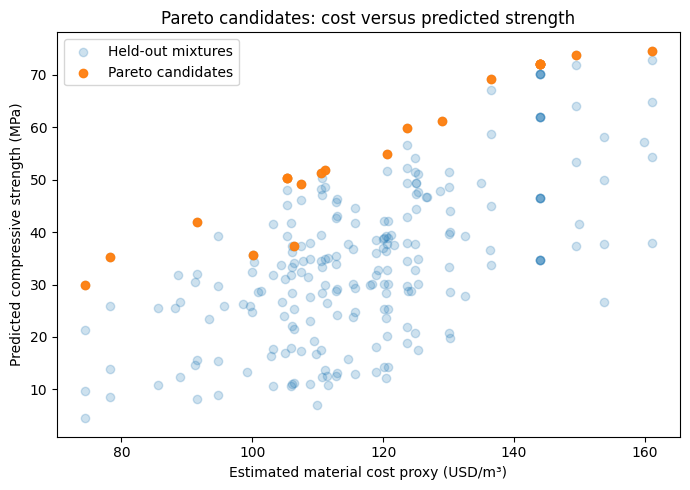

Saved: /content/drive/MyDrive/Indigo Research Project/figures/pareto_candidates_cost_baseline.png
Top Pareto candidates ordered by emissions, cost, and predicted strength:


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,actual_strength_mpa,pred_strength_mpa,co2_proxy_kg_per_m3,cost_proxy_usd_per_m3
0,102.0,153.0,0.0,192.0,0.0,887.0,942.0,90,25.46,29.874635,198.870632,74.457460
1,116.0,173.0,0.0,192.0,0.0,909.8,891.9,90,31.02,35.173036,213.214832,78.226444
2,150.0,236.8,0.0,173.8,11.9,1069.3,674.8,28,37.43,35.731231,254.195065,100.050750
3,166.1,0.0,163.3,176.5,4.5,1058.6,780.1,100,33.54,37.333234,260.794294,106.313708
4,166.8,250.2,0.0,203.5,0.0,975.6,692.6,90,43.57,41.923308,264.343686,91.485848
5,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,100,48.15,51.895314,267.370127,111.087136
6,167.4,129.9,128.6,175.5,7.8,1006.3,746.6,100,53.66,51.343823,272.564498,110.450146
7,213.8,98.1,24.5,181.7,6.7,1066.0,785.5,100,49.97,49.120478,299.353413,107.403768
8,218.9,0.0,124.1,158.5,11.3,1078.7,794.9,100,46.23,54.814708,306.800166,120.528738
9,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,100,63.53,59.901166,313.864797,123.570062


In [ ]:
# Checks for required data before running the code
# Sets up cost and emission data with variables in UCI dataset for analysis
if RUN_SUSTAINABILITY_ANALYSIS:
    factor_path = DATA_DIR / "sustainability_factors.csv"

    if not factor_path.exists():
        raise FileNotFoundError(
            f"Missing sustainability factor file: {factor_path}"
        )

    factor_df = pd.read_csv(factor_path)

    # Checks if all required columns are present in the dataset
    required_factor_columns = {
        "material",
        "co2_kg_per_kg",
        "cost_usd_per_kg",
        "source",
        "year",
        "geography",
    }
    missing_factor_columns = required_factor_columns - set(factor_df.columns)
    if missing_factor_columns:
        raise ValueError(
            f"Factor table is missing columns: {sorted(missing_factor_columns)}"
        )

    # Checks if cost and emissions factors are numeric and reasonable
    # Attempts to coerce factors before reporting an error
    factor_df["material"] = factor_df["material"].astype(str).str.strip()
    for column in ["co2_kg_per_kg", "cost_usd_per_kg"]:
        factor_df[column] = pd.to_numeric(factor_df[column], errors="coerce")

    if factor_df[["co2_kg_per_kg", "cost_usd_per_kg"]].isna().any().any():
        raise ValueError(
            "All emissions and cost factors must be numeric and complete."
        )

    if (factor_df[["co2_kg_per_kg", "cost_usd_per_kg"]] < 0).any().any():
        raise ValueError("Sustainability factors cannot be negative.")

    # Defines all the required materials, then searches if any are missing in
    # the dataset
    mixture_materials = [
        "cement",
        "blast_furnace_slag",
        "fly_ash",
        "water",
        "superplasticizer",
        "coarse_aggregate",
        "fine_aggregate",
    ]

    factor_df = factor_df.set_index("material")
    missing_materials = [
        material for material in mixture_materials
        if material not in factor_df.index
    ]
    if missing_materials:
        raise ValueError(
            f"Missing sustainability factors for: {missing_materials}"
        )

    # Defines factors for later usage
    co2_factors = factor_df["co2_kg_per_kg"].to_dict()
    cost_factors = factor_df["cost_usd_per_kg"].to_dict()

    # Used to calculate total cost and emissions for each row in the dataset
    def weighted_proxy(frame: pd.DataFrame, factors: dict) -> pd.Series:
        total = np.zeros(len(frame), dtype=float)
        for material in mixture_materials:
            total += (
                frame[material].to_numpy(dtype=float)
                * float(factors[material])
            )
        return pd.Series(total, index=frame.index)

    # Checks all the rows in the current dataset for cost, emissions, and strength
    # Discards rows that are strictly worse in these three metrics
    def nondominated_mask(
        emissions: np.ndarray,
        costs: np.ndarray,
        strengths: np.ndarray,
    ) -> np.ndarray:
        keep = np.ones(len(strengths), dtype=bool)

        for i in range(len(strengths)):
            dominates_i = (
                (emissions <= emissions[i])
                & (costs <= costs[i])
                & (strengths >= strengths[i])
                & (
                    (emissions < emissions[i])
                    | (costs < costs[i])
                    | (strengths > strengths[i])
                )
            )
            if dominates_i.any():
                keep[i] = False

        return keep

# Held-out rows only, so all displayed strength predictions are out-of-sample.
    df_proxy = df.loc[X_test.index].copy()

    # Uses selected machine learning model (gradient boosting)
    # Performs predictions and accuracy comparisons
    df_proxy["pred_strength_mpa"] = selected_model.predict(X_test)
    df_proxy["actual_strength_mpa"] = y_test.to_numpy()

    # Computes emissions and costs
    df_proxy["co2_proxy_kg_per_m3"] = weighted_proxy(
        df_proxy, co2_factors
    )
    df_proxy["cost_proxy_usd_per_m3"] = weighted_proxy(
        df_proxy, cost_factors
    )

    # Saves sustainability results to a CSV for publication
    proxy_table_path = (
        OUT_DIR / f"sustainability_results_{OUTPUT_PREFIX}.csv"
    )
    df_proxy.to_csv(proxy_table_path, index=False)
    print("Saved:", proxy_table_path)

    # Graphs proxy analysis for held-out mixtures
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        df_proxy["co2_proxy_kg_per_m3"],
        df_proxy["pred_strength_mpa"],
        alpha=0.60,
    )
    ax.set_xlabel("Estimated emissions proxy (kg CO₂e/m³)")
    ax.set_ylabel("Predicted compressive strength (MPa)")
    ax.set_title("Held-out mixtures: strength versus emissions proxy")
    fig.tight_layout()
    co2_path = (
        FIG_DIR / f"tradeoff_strength_vs_co2_proxy_{OUTPUT_PREFIX}.png"
    )
    fig.savefig(co2_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", co2_path)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        df_proxy["cost_proxy_usd_per_m3"],
        df_proxy["pred_strength_mpa"],
        alpha=0.60,
    )
    ax.set_xlabel("Estimated material cost proxy (USD/m³)")
    ax.set_ylabel("Predicted compressive strength (MPa)")
    ax.set_title("Held-out mixtures: strength versus cost proxy")
    fig.tight_layout()
    cost_path = (
        FIG_DIR / f"tradeoff_strength_vs_cost_proxy_{OUTPUT_PREFIX}.png"
    )
    fig.savefig(cost_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", cost_path)

# Identifies, sorts, then saves Pareto optimal solutions
    # Evaluates all CSV rows and determines nondominated candidate mixtures
    # within the observed dataset (Pareto candidates)
    pareto_mask = nondominated_mask(
        df_proxy["co2_proxy_kg_per_m3"].to_numpy(),
        df_proxy["cost_proxy_usd_per_m3"].to_numpy(),
        df_proxy["pred_strength_mpa"].to_numpy(),
    )

    # Clears non-Pareto optimal solutions and ranks Pareto candidates
    pareto_candidates = (
        df_proxy.loc[pareto_mask]
        .sort_values(
            [
                "co2_proxy_kg_per_m3",
                "cost_proxy_usd_per_m3",
                "pred_strength_mpa",
            ],
            ascending=[True, True, False],
        )
        .reset_index(drop=True)
    )

    # Saves results as a CSV in outputs for publication
    pareto_table_path = (
        OUT_DIR / f"pareto_candidates_{OUTPUT_PREFIX}.csv"
    )
    pareto_candidates.to_csv(pareto_table_path, index=False)
    print("Saved:", pareto_table_path)
    print("Number of Pareto candidates:", len(pareto_candidates))

    # Creates a Pareto candidate graph for publication
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        df_proxy["co2_proxy_kg_per_m3"],
        df_proxy["pred_strength_mpa"],
        alpha=0.22,
        label="Held-out mixtures",
    )
    ax.scatter(
        pareto_candidates["co2_proxy_kg_per_m3"],
        pareto_candidates["pred_strength_mpa"],
        alpha=0.95,
        label="Pareto candidates",
    )
    ax.set_xlabel("Estimated emissions proxy (kg CO₂e/m³)")
    ax.set_ylabel("Predicted compressive strength (MPa)")
    ax.set_title(
        "Pareto candidates within the observed held-out dataset"
    )
    ax.legend()
    fig.tight_layout()

    pareto_fig_path = (
        FIG_DIR / f"pareto_candidates_{OUTPUT_PREFIX}.png"
    )
    fig.savefig(pareto_fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", pareto_fig_path)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        df_proxy["cost_proxy_usd_per_m3"],
        df_proxy["pred_strength_mpa"],
        alpha=0.22,
        label="Held-out mixtures",
    )
    ax.scatter(
        pareto_candidates["cost_proxy_usd_per_m3"],
        pareto_candidates["pred_strength_mpa"],
        alpha=0.95,
        label="Pareto candidates",
    )
    ax.set_xlabel("Estimated material cost proxy (USD/m³)")
    ax.set_ylabel("Predicted compressive strength (MPa)")
    ax.set_title("Pareto candidates: cost versus predicted strength")
    ax.legend()
    fig.tight_layout()

    pareto_cost_fig_path = (
        FIG_DIR / f"pareto_candidates_cost_{OUTPUT_PREFIX}.png"
    )
    fig.savefig(
        pareto_cost_fig_path,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    print("Saved:", pareto_cost_fig_path)

    # Creates a table of the top Pareto candidates for viewing
    display_columns = [
        "cement",
        "blast_furnace_slag",
        "fly_ash",
        "water",
        "superplasticizer",
        "coarse_aggregate",
        "fine_aggregate",
        "age",
        "actual_strength_mpa",
        "pred_strength_mpa",
        "co2_proxy_kg_per_m3",
        "cost_proxy_usd_per_m3",
    ]

    print(
        "Top Pareto candidates ordered by emissions, cost, "
        "and predicted strength:"
    )
    display(pareto_candidates[display_columns].head(15))

**Tradeoff Scatterplots (Proxy Analysis):** Although a positive relationship exists between increasing cost/CO₂ and increasing concrete compressive strength, it is clear that a non-linear relationship exists between cost/CO₂ and predicted strength. This indicates that there are many different mixtures to optimize either factor based on the chosen features.

**Pareto Candidates Scatterplot (Proxy Analysis):** The baseline Pareto analysis demonstrates that there is an observed tradeoff between an increase in a mixture’s CO₂ emissions and its compressive strength. Figure 13 demonstrates this by highlighting the Pareto candidates with the highest levels of CO₂ also subsequently having the highest level of compressive strength. The Pareto candidates for the cost proxy do not show a similar relationship, with similar compressive strength mixtures existing at different magnitudes of material costs. Although an upward trend between compressive strength and cost exists to some extent, lower-cost mixture alternatives exist around concrete compressive strengths of 40-55 MPa.

## 12) Method Overview

**Dataset:** UCI Concrete Compressive Strength baseline dataset with mixture composition features (kg/m³) and curing age (days).

**Inputs:** eight explicit mixture and curing-age features.

**Target:** compressive strength (MPa).  

**Model Selection:** training-set cross-validation only.

**Evaluation:** 5-fold cross-validation on one held-out test set using R² and mean absolute error (MAE).  

**Tuning:** small grid search over key hyperparameters for tree-based models.  

**Model interpretation:** permutation importance computed on the test set for the best-performing model.  

**Sustainability Analysis:** held-out predictions combined with unit-consistent literature-informed working factors.

**Pareto analysis:** three-objective nondominated set that minimizes emissions and cost while maximizing predicted strength.

**Pareto interpretation:** Pareto rows are candidate mixtures within the observed held-out dataset, not guaranteed global optimal.

**Future phase:** a separate RCA-specific notebook and dataset will be developed after the baseline is stabilized

